# Notebook 02: Exploratory Data Analysis (EDA)

## Project: Retail Sales Intelligence

### 1. Introduction

This notebook performs exploratory data analysis on the retail sales dataset to evaluate commercial performance, identify revenue drivers and generate actionable business insights.

The analysis builds on the cleaned datasets prepared in Notebook 01.

### Objectives

1. Integrate sales, product, customer and store datasets.
2. Validate data quality and relationships between datasets.
3. Engineer financial and analytical features.
4. Examine overall sales and revenue performance.
5. Identify temporal sales trends and patterns.
6. Evaluate product and category performance.
7. Analyse customer purchasing behaviour.
8. Investigate geographical sales performance.
9. Assess product profitability.
10. Generate business insights to support management decisions.

### Analytical Approach

The analysis uses Python, Pandas, NumPy and Matplotlib.

Financial performance will be measured using revenue, product costs, gross profit and gross profit margin.

All product prices and costs will be converted into numeric USD values before financial calculations are performed.

### Expected Outputs

The notebook will produce validated analytical datasets and summary tables for the development of an interactive Power BI dashboard.

## 2. Import Libraries and Configure Project Paths

Import the Python libraries required for data manipulation, statistical analysis and visualisation.

Project paths are configured relative to the main project directory to maintain reproducibility across different environments.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

# Configure display options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Configure project directories
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

EDA_OUTPUT_DIR = PROCESSED_DIR / "eda_outputs"

EDA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR.resolve())
print("Raw data directory:", RAW_DIR.resolve())
print("Processed data directory:", PROCESSED_DIR.resolve())
print("EDA output directory:", EDA_OUTPUT_DIR.resolve())

Project directory: C:\Users\Administrator\retail-sales-intelligence
Raw data directory: C:\Users\Administrator\retail-sales-intelligence\data\raw
Processed data directory: C:\Users\Administrator\retail-sales-intelligence\data\processed
EDA output directory: C:\Users\Administrator\retail-sales-intelligence\data\processed\eda_outputs


## 3. Load Analytical Datasets

Load the sales, product, customer, store and exchange-rate datasets.

The processed directory is prioritised because Notebook 01 is responsible for data cleaning and preparation.

If a cleaned version is not found, the loader falls back to the original raw CSV file. This ensures that the notebook can locate the available source datasets without requiring hardcoded absolute file paths.

Exchange rates are retained for reference, but product prices and costs already expressed in USD will not be converted again.

In [2]:
# Locate datasets, prioritising processed files

def locate_dataset(dataset_name, raw_filename):

    candidates = [
        PROCESSED_DIR / f"{dataset_name}_clean.csv",
        PROCESSED_DIR / f"{dataset_name.lower()}_clean.csv",
        PROCESSED_DIR / f"{dataset_name}.csv",
        RAW_DIR / raw_filename
    ]

    for path in candidates:
        if path.exists():
            print(f"{dataset_name}: {path.name}")
            return path

    raise FileNotFoundError(
        f"Could not locate {dataset_name}. "
        f"Check the files in {PROCESSED_DIR} and {RAW_DIR}."
    )


# Locate source files
sales_path = locate_dataset("Sales", "Sales.csv")
products_path = locate_dataset("Products", "Products.csv")
customers_path = locate_dataset("Customers", "Customers.csv")
stores_path = locate_dataset("Stores", "Stores.csv")
exchange_path = locate_dataset("Exchange_Rates", "Exchange_Rates.csv")


# Load datasets
sales = pd.read_csv(sales_path)
products = pd.read_csv(products_path)
customers = pd.read_csv(customers_path)
stores = pd.read_csv(stores_path)
exchange_rates = pd.read_csv(exchange_path)


# Display loading summary
datasets = {
    "Sales": sales,
    "Products": products,
    "Customers": customers,
    "Stores": stores,
    "Exchange Rates": exchange_rates
}

print("\nDATASET LOADING SUMMARY")
print("=" * 55)

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Sales: Sales_clean.csv
Products: Products_clean.csv
Customers: Customers_clean.csv
Stores: Stores_clean.csv
Exchange_Rates: Exchange_Rates_clean.csv

DATASET LOADING SUMMARY
Sales: 62,884 rows, 9 columns
Products: 2,517 rows, 10 columns
Customers: 15,266 rows, 10 columns
Stores: 67 rows, 5 columns
Exchange Rates: 11,215 rows, 3 columns


## 4. Initial Data Inspection

Examine the structure and characteristics of each dataset before integration.

The inspection evaluates:

- Dataset dimensions.
- Column names and data types.
- Missing observations.
- Duplicate records.
- Sample records.

This stage establishes an understanding of the available data and helps identify potential issues that could affect subsequent analysis.

In [3]:
# Inspect dataset structures

for name, df in datasets.items():

    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    print("Dataset shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    display(df.dtypes.to_frame("Data Type"))

    print("\nFirst five records:")
    display(df.head())


SALES
Dataset shape: (62884, 9)

Column names:
['order_number', 'line_item', 'order_date', 'delivery_date', 'customer_key', 'store_key', 'product_key', 'quantity', 'currency_code']

Data types:


,Data Type
order_number,int64
line_item,int64
order_date,object
delivery_date,object
customer_key,int64
store_key,int64
product_key,int64
quantity,int64
currency_code,object



First five records:


,order_number,line_item,order_date,delivery_date,customer_key,store_key,product_key,quantity,currency_code
0,366000,1,2016-01-01,NaN,265598,10,1304,1,CAD
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD



PRODUCTS
Dataset shape: (2517, 10)

Column names:
['product_key', 'product_name', 'brand', 'color', 'unit_cost_usd', 'unit_price_usd', 'subcategory_key', 'subcategory', 'category_key', 'category']

Data types:


,Data Type
product_key,int64
product_name,object
brand,object
color,object
unit_cost_usd,object
unit_price_usd,object
subcategory_key,int64
subcategory,object
category_key,int64
category,object


... (10 outputs left out)


EXCHANGE RATES
Dataset shape: (11215, 3)

Column names:
['date', 'currency', 'exchange']

Data types:


,Data Type
date,object
currency,object
exchange,float64



First five records:


,date,currency,exchange
0,2015-01-01,USD,1.00
1,2015-01-01,CAD,1.16
2,2015-01-01,AUD,1.22
3,2015-01-01,EUR,0.82
4,2015-01-01,GBP,0.64


In [4]:
# Examine missing values and duplicate records

quality_summary = []

for name, df in datasets.items():

    quality_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Duplicate Rows": df.duplicated().sum(),
        "Missing Values": df.isna().sum().sum()
    })

quality_summary = pd.DataFrame(quality_summary)

display(quality_summary)

,Dataset,Rows,Columns,Duplicate Rows,Missing Values
0,Sales,62884,9,0,49719
1,Products,2517,10,0,0
2,Customers,15266,10,0,10
3,Stores,67,5,0,1
4,Exchange Rates,11215,3,0,0


## 5. Data Integration and Validation

Integrate the sales dataset with the product, customer and store datasets using their respective primary and foreign keys.

The integration creates a unified transaction-level dataset for commercial analysis.

The following relationships are used:

- Sales to Products: product_key
- Sales to Customers: customer_key
- Sales to Stores: store_key

### Data Integration Controls

To protect the integrity of the transaction data:

1. Check that dimension-table keys are unique.
2. Identify unmatched transaction records.
3. Validate the number of records after each merge.
4. Use many-to-one merge validation.
5. Preserve the original sales transaction count.

The resulting dataset should contain the original sales records enriched with relevant product, customer and store attributes.

In [5]:
# Validate required integration keys

required_keys = {
    "sales": ["product_key", "customer_key", "store_key"],
    "products": ["product_key"],
    "customers": ["customer_key"],
    "stores": ["store_key"]
}

for dataset_name, columns in required_keys.items():

    df = datasets[dataset_name.capitalize()]

    missing_columns = [
        col for col in columns
        if col not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{dataset_name} is missing required columns: "
            f"{missing_columns}"
        )

print("All required integration keys are present.")


# Check dimension key uniqueness

for name, df, key in [
    ("Products", products, "product_key"),
    ("Customers", customers, "customer_key"),
    ("Stores", stores, "store_key")
]:

    duplicates = df[key].duplicated().sum()

    print(f"{name} duplicate keys: {duplicates}")

    if duplicates > 0:
        raise ValueError(
            f"{name} contains duplicate {key} values. "
            "Resolve these before merging."
        )

All required integration keys are present.
Products duplicate keys: 0
Customers duplicate keys: 0
Stores duplicate keys: 0


In [6]:
# Preserve original transaction count

original_sales_count = len(sales)

# Check unmatched dimension keys before merging

match_checks = {
    "Products": (
        "product_key",
        products["product_key"]
    ),
    "Customers": (
        "customer_key",
        customers["customer_key"]
    ),
    "Stores": (
        "store_key",
        stores["store_key"]
    )
}

for name, (key, dimension_keys) in match_checks.items():

    unmatched = (
        ~sales[key].isin(dimension_keys)
    ).sum()

    print(f"{name} unmatched sales records: {unmatched:,}")

Products unmatched sales records: 0
Customers unmatched sales records: 0
Stores unmatched sales records: 0


In [7]:
# Integrate sales and product information

sales_enriched = sales.merge(
    products,
    on="product_key",
    how="left",
    validate="many_to_one",
    indicator="_product_match"
)

print("After product integration:", len(sales_enriched))


# Integrate customer information
sales_enriched = sales_enriched.merge(
    customers,
    on="customer_key",
    how="left",
    validate="many_to_one",
    indicator="_customer_match"
)

print("After customer integration:", len(sales_enriched))


# Integrate store information
sales_enriched = sales_enriched.merge(
    stores,
    on="store_key",
    how="left",
    validate="many_to_one",
    indicator="_store_match"
)

print("After store integration:", len(sales_enriched))

After product integration: 62884
After customer integration: 62884
After store integration: 62884


In [8]:
# Evaluate integration results

for col in [
    "_product_match",
    "_customer_match",
    "_store_match"
]:

    print("\n" + col.upper())

    display(
        sales_enriched[col].value_counts(
            dropna=False
        )
    )


# Verify transaction preservation
assert len(sales_enriched) == original_sales_count, (
    "Transaction count changed during integration."
)

# Remove merge indicators after validation
sales_enriched.drop(
    columns=[
        "_product_match",
        "_customer_match",
        "_store_match"
    ],
    inplace=True
)

print("\nIntegration validation successful.")
print("Original sales records:", original_sales_count)
print("Integrated sales records:", len(sales_enriched))


_PRODUCT_MATCH


_product_match
both          62884
left_only         0
right_only        0
Name: count, dtype: int64


_CUSTOMER_MATCH


_customer_match
both          62884
left_only         0
right_only        0
Name: count, dtype: int64


_STORE_MATCH


_store_match
both          62884
left_only         0
right_only        0
Name: count, dtype: int64


Integration validation successful.
Original sales records: 62884
Integrated sales records: 62884


## 6. Feature Engineering and Financial Calculations

Feature engineering transforms the integrated transaction data into commercially meaningful analytical variables.

### Financial Metrics

The following metrics are calculated:

- Revenue = Quantity × Unit Selling Price
- Product Cost = Quantity × Unit Cost
- Gross Profit = Revenue − Product Cost
- Gross Profit Margin = (Gross Profit / Revenue) × 100

### Data Type Correction

Product prices and costs are originally stored as currency strings containing dollar signs.

These values must be cleaned and converted into numeric USD values before calculations.

This step is essential to prevent invalid financial results and missing observations.

The resulting metrics will be used throughout the subsequent commercial performance analysis.

In [9]:
# Clean currency fields before financial calculations

def clean_currency(series):

    cleaned = (
        series.astype("string")
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    return pd.to_numeric(cleaned, errors="coerce")


# Restore product prices and costs directly from the original
# product dataset to avoid carrying forward invalid merged values.

product_price_lookup = products.set_index("product_key")

sales_enriched["unit_price_usd"] = (
    sales_enriched["product_key"]
    .map(product_price_lookup["unit_price_usd"])
)

sales_enriched["unit_cost_usd"] = (
    sales_enriched["product_key"]
    .map(product_price_lookup["unit_cost_usd"])
)


# Convert prices and costs to numeric values

sales_enriched["unit_price_usd"] = clean_currency(
    sales_enriched["unit_price_usd"]
)

sales_enriched["unit_cost_usd"] = clean_currency(
    sales_enriched["unit_cost_usd"]
)


# Convert quantity to numeric
sales_enriched["quantity"] = pd.to_numeric(
    sales_enriched["quantity"],
    errors="coerce"
)


print("Financial data type conversion completed.")

display(
    sales_enriched[
        [
            "quantity",
            "unit_price_usd",
            "unit_cost_usd"
        ]
    ].head(10)
)

Financial data type conversion completed.


,quantity,unit_price_usd,unit_cost_usd
0,1,68.00,31.27
1,2,427.00,141.47
2,1,665.94,220.64
3,7,322.00,148.08
4,1,326.00,166.20
5,4,646.00,214.03
6,6,"1,592.20",527.53
7,2,255.00,117.27
8,4,469.00,215.68
9,1,57.99,26.67


In [10]:
# Calculate commercial performance metrics

sales_enriched["revenue_usd"] = (
    sales_enriched["quantity"] *
    sales_enriched["unit_price_usd"]
)

sales_enriched["product_cost_usd"] = (
    sales_enriched["quantity"] *
    sales_enriched["unit_cost_usd"]
)

sales_enriched["gross_profit_usd"] = (
    sales_enriched["revenue_usd"] -
    sales_enriched["product_cost_usd"]
)

sales_enriched["gross_profit_margin"] = np.where(
    sales_enriched["revenue_usd"] != 0,
    (
        sales_enriched["gross_profit_usd"] /
        sales_enriched["revenue_usd"]
    ) * 100,
    np.nan
)


print("Commercial performance metrics calculated.")

display(
    sales_enriched[
        [
            "quantity",
            "unit_price_usd",
            "unit_cost_usd",
            "revenue_usd",
            "product_cost_usd",
            "gross_profit_usd",
            "gross_profit_margin"
        ]
    ].head(10)
)

Commercial performance metrics calculated.


,quantity,unit_price_usd,unit_cost_usd,revenue_usd,product_cost_usd,gross_profit_usd,gross_profit_margin
0,1,68.00,31.27,68.00,31.27,36.73,54.01
1,2,427.00,141.47,854.00,282.94,571.06,66.87
2,1,665.94,220.64,665.94,220.64,445.30,66.87
3,7,322.00,148.08,"2,254.00","1,036.56","1,217.44",54.01
4,1,326.00,166.20,326.00,166.20,159.80,49.02
5,4,646.00,214.03,"2,584.00",856.12,"1,727.88",66.87
6,6,"1,592.20",527.53,"9,553.20","3,165.18","6,388.02",66.87
7,2,255.00,117.27,510.00,234.54,275.46,54.01
8,4,469.00,215.68,"1,876.00",862.72,"1,013.28",54.01
9,1,57.99,26.67,57.99,26.67,31.32,54.01


In [11]:
# Validate financial calculations

financial_columns = [
    "unit_price_usd",
    "unit_cost_usd",
    "revenue_usd",
    "product_cost_usd",
    "gross_profit_usd",
    "gross_profit_margin"
]

financial_validation = pd.DataFrame({
    "Column": financial_columns,
    "Valid Records": [
        sales_enriched[col].notna().sum()
        for col in financial_columns
    ],
    "Missing Records": [
        sales_enriched[col].isna().sum()
        for col in financial_columns
    ]
})

display(financial_validation)


# Verify financial calculations
assert sales_enriched["unit_price_usd"].notna().any()
assert sales_enriched["unit_cost_usd"].notna().any()

assert np.allclose(
    sales_enriched["gross_profit_usd"].dropna(),
    (
        sales_enriched["revenue_usd"] -
        sales_enriched["product_cost_usd"]
    ).dropna()
)

print("Financial calculation validation passed.")

,Column,Valid Records,Missing Records
0,unit_price_usd,62884,0
1,unit_cost_usd,62884,0
2,revenue_usd,62884,0
3,product_cost_usd,62884,0
4,gross_profit_usd,62884,0
5,gross_profit_margin,62884,0


Financial calculation validation passed.


## 7. Descriptive Statistical Analysis

Descriptive statistics summarise the distribution and characteristics of the integrated retail data.

The analysis examines transaction quantities, product prices, product costs, revenue, gross profit and gross profit margins.

Statistical measures include:

- Count
- Mean
- Standard deviation
- Minimum
- Median
- Maximum
- Quartiles

These measures provide an overview of transaction characteristics and commercial performance.

In [12]:
# Generate descriptive statistics

commercial_variables = [
    "quantity",
    "unit_price_usd",
    "unit_cost_usd",
    "revenue_usd",
    "product_cost_usd",
    "gross_profit_usd",
    "gross_profit_margin"
]

descriptive_statistics = (
    sales_enriched[commercial_variables]
    .describe()
    .T
)

display(descriptive_statistics)

,count,mean,std,min,25%,50%,75%,max
quantity,"62,884.00",3.14,2.26,1.00,1.00,2.00,4.00,10.00
unit_price_usd,"62,884.00",280.57,382.83,0.95,47.95,181.00,300.00,"3,199.99"
unit_cost_usd,"62,884.00",116.25,140.03,0.48,22.05,79.53,138.42,"1,060.22"
revenue_usd,"62,884.00",886.64,"1,648.48",0.95,115.00,360.00,969.00,"31,999.90"
product_cost_usd,"62,884.00",367.23,614.55,0.48,52.88,164.16,423.08,"10,602.20"
gross_profit_usd,"62,884.00",519.41,"1,052.20",0.47,61.56,194.44,540.14,"21,397.70"
gross_profit_margin,"62,884.00",54.90,6.41,48.95,49.02,54.01,54.02,66.89


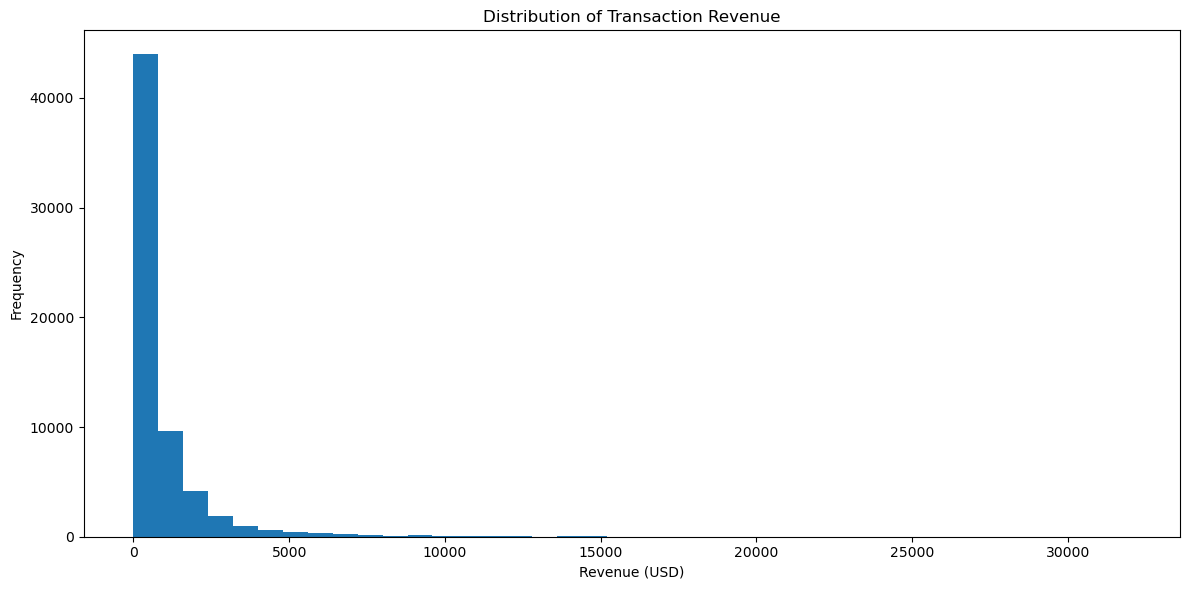

In [13]:
# Visualise transaction revenue distribution

revenue_data = sales_enriched[
    "revenue_usd"
].dropna()

plt.figure(figsize=(12, 6))

plt.hist(revenue_data, bins=40)

plt.title("Distribution of Transaction Revenue")
plt.xlabel("Revenue (USD)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 8. Overall Sales and Revenue Analysis

This section evaluates the overall commercial performance of the retailer.

Key performance indicators include:

- Total revenue.
- Total orders.
- Total units sold.
- Average order value.
- Total product costs.
- Gross profit.
- Gross profit margin.

Orders are counted distinctly using order_number to avoid counting individual product line items as separate orders.

These indicators provide management with a high-level view of the retailer's financial and operational performance.

In [14]:
# Calculate overall retail KPIs

total_revenue = sales_enriched["revenue_usd"].sum()

total_product_cost = sales_enriched[
    "product_cost_usd"
].sum()

total_gross_profit = sales_enriched[
    "gross_profit_usd"
].sum()

total_units = sales_enriched["quantity"].sum()

total_orders = (
    sales_enriched["order_number"].nunique()
    if "order_number" in sales_enriched.columns
    else np.nan
)

average_order_value = (
    total_revenue / total_orders
    if pd.notna(total_orders) and total_orders > 0
    else np.nan
)

overall_gross_margin = (
    total_gross_profit / total_revenue * 100
    if total_revenue > 0
    else np.nan
)


kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue (USD)",
        "Total Orders",
        "Total Units Sold",
        "Average Order Value (USD)",
        "Total Product Cost (USD)",
        "Gross Profit (USD)",
        "Gross Profit Margin (%)"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_units,
        average_order_value,
        total_product_cost,
        total_gross_profit,
        overall_gross_margin
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Revenue (USD),"55,755,479.59"
1,Total Orders,"26,326.00"
2,Total Units Sold,"197,757.00"
3,Average Order Value (USD),"2,117.89"
4,Total Product Cost (USD),"23,092,791.21"
5,Gross Profit (USD),"32,662,688.38"
6,Gross Profit Margin (%),58.58


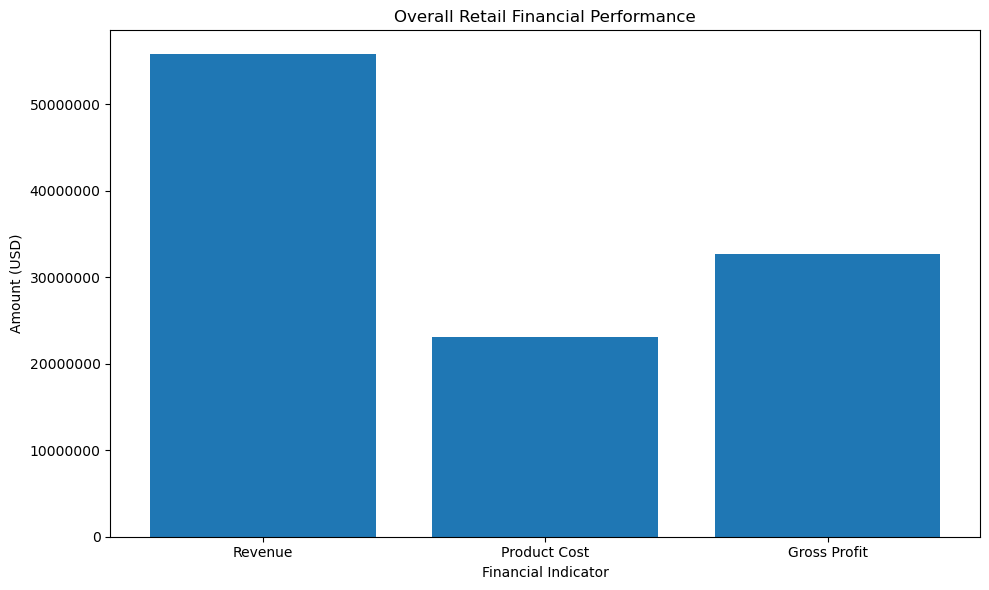

In [15]:
# Visualise overall financial performance

financial_labels = [
    "Revenue",
    "Product Cost",
    "Gross Profit"
]

financial_values = [
    total_revenue,
    total_product_cost,
    total_gross_profit
]

plt.figure(figsize=(10, 6))

plt.bar(financial_labels, financial_values)

plt.title("Overall Retail Financial Performance")
plt.xlabel("Financial Indicator")
plt.ylabel("Amount (USD)")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

## 9. Temporal Sales Analysis

This section investigates changes in retail sales performance over time.

The order date is used to derive:

- Year.
- Month.
- Month name.
- Year-month period.
- Quarter.

Monthly and annual revenue patterns are examined to identify periods of stronger or weaker commercial performance.

Temporal analysis can support revenue planning, promotional strategies and inventory management.

In [16]:
# Prepare transaction dates

sales_enriched["order_date"] = pd.to_datetime(
    sales_enriched["order_date"],
    errors="coerce"
)

temporal_sales = sales_enriched.dropna(
    subset=["order_date"]
).copy()

# Create time-based features

temporal_sales["year"] = (
    temporal_sales["order_date"].dt.year
)

temporal_sales["month"] = (
    temporal_sales["order_date"].dt.month
)

temporal_sales["month_name"] = (
    temporal_sales["order_date"].dt.month_name()
)

temporal_sales["year_month"] = (
    temporal_sales["order_date"].dt.to_period("M")
)

temporal_sales["quarter"] = (
    temporal_sales["order_date"].dt.to_period("Q")
)

print("Temporal features created.")

display(
    temporal_sales[
        [
            "order_date",
            "year",
            "month",
            "month_name",
            "year_month",
            "quarter"
        ]
    ].head()
)

Temporal features created.


,order_date,year,month,month_name,year_month,quarter
0,2016-01-01,2016,1,January,2016-01,2016Q1
1,2016-01-01,2016,1,January,2016-01,2016Q1
2,2016-01-01,2016,1,January,2016-01,2016Q1
3,2016-01-01,2016,1,January,2016-01,2016Q1
4,2016-01-01,2016,1,January,2016-01,2016Q1


In [17]:
# Monthly sales performance

monthly_sales = (
    temporal_sales
    .groupby("year_month")
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        units_sold=("quantity", "sum"),
        orders=("order_number", "nunique")
    )
    .reset_index()
)

monthly_sales["year_month"] = (
    monthly_sales["year_month"].astype(str)
)

display(monthly_sales.head(15))

,year_month,revenue_usd,gross_profit_usd,product_cost_usd,units_sold,orders
0,2016-01,"649,918.78","388,268.96","261,649.82",2116,292
1,2016-02,"891,098.30","531,722.75","359,375.55",2676,334
2,2016-03,"338,407.36","203,506.99","134,900.37",895,109
3,2016-04,"110,591.63","66,231.19","44,360.44",326,41
4,2016-05,"595,986.18","356,049.32","239,936.86",1646,220
5,2016-06,"518,585.28","294,270.49","224,314.79",1864,243
6,2016-07,"454,959.83","269,369.43","185,590.40",1572,201
7,2016-08,"547,512.69","325,909.91","221,602.78",1611,229
8,2016-09,"567,421.12","331,859.55","235,561.57",1885,262
9,2016-10,"623,959.57","365,597.98","258,361.59",2042,258


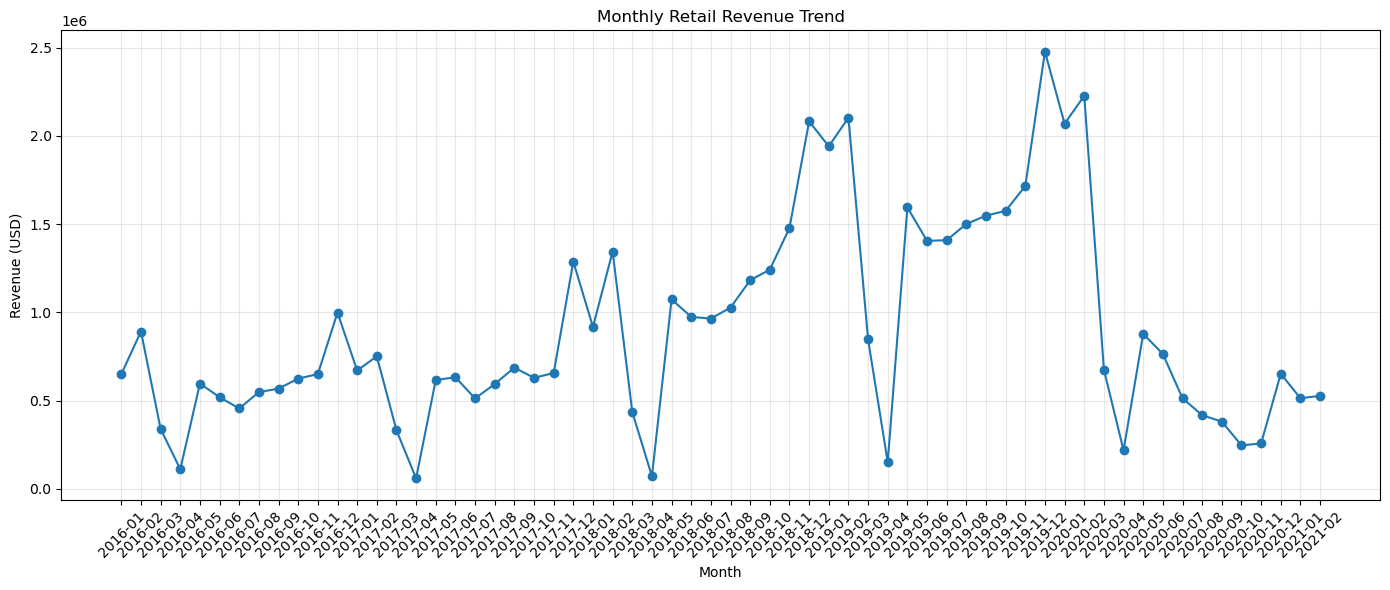

In [18]:
# Plot monthly revenue trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["year_month"],
    monthly_sales["revenue_usd"],
    marker="o"
)

plt.title("Monthly Retail Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

,year,revenue_usd,gross_profit_usd,product_cost_usd,units_sold,orders
0,2016,"6,946,793.56","4,107,000.47","2,839,793.09",21761,2865
1,2017,"7,421,422.27","4,337,064.06","3,084,358.21",24798,3280
2,2018,"12,788,960.66","7,464,961.11","5,323,999.55",44498,5965
3,2019,"18,264,382.48","10,697,738.90","7,566,643.58",68440,9083
4,2020,"9,294,632.14","5,447,460.15","3,847,171.99",34463,4635
5,2021,"1,039,288.48","608,463.69","430,824.79",3797,498


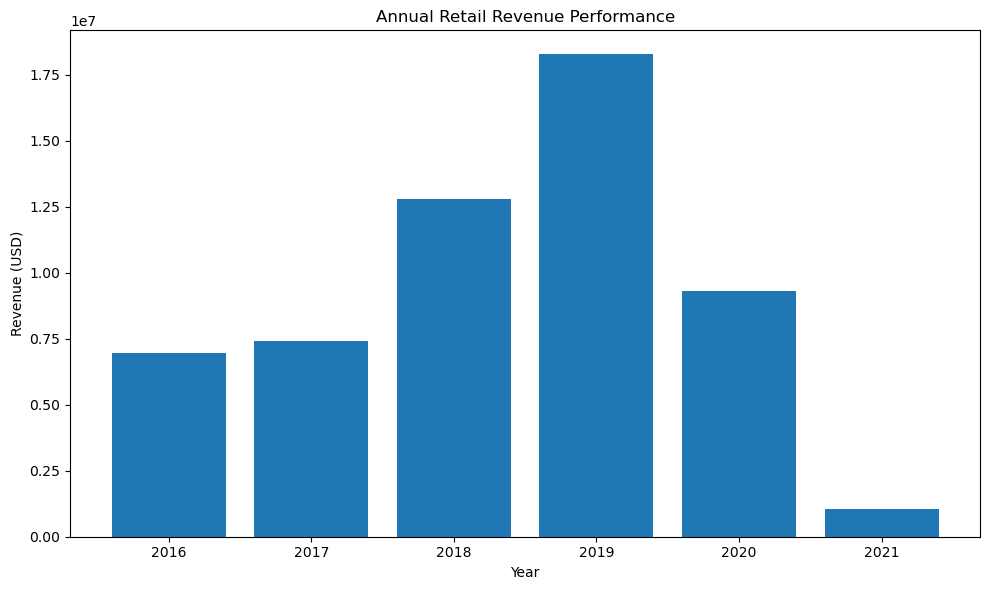

In [19]:
# Annual sales performance

yearly_sales = (
    temporal_sales
    .groupby("year")
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        units_sold=("quantity", "sum"),
        orders=("order_number", "nunique")
    )
    .reset_index()
)

display(yearly_sales)

plt.figure(figsize=(10, 6))

plt.bar(
    yearly_sales["year"].astype(str),
    yearly_sales["revenue_usd"]
)

plt.title("Annual Retail Revenue Performance")
plt.xlabel("Year")
plt.ylabel("Revenue (USD)")

plt.tight_layout()
plt.show()

## 10. Product and Category Performance Analysis

This section evaluates the contribution of individual products and product categories to retail performance.

The analysis identifies:

- Highest-revenue product categories.
- Highest-revenue individual products.
- Most frequently purchased products.
- Product categories generating the greatest gross profit.
- Differences between sales volume and profitability.

Both revenue and gross profit are considered because high sales volume does not necessarily indicate high profitability.

The findings can support product portfolio management, pricing decisions and inventory prioritisation.

In [20]:
# Analyse performance by product category

category_performance = (
    sales_enriched
    .groupby("category", dropna=False)
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        units_sold=("quantity", "sum"),
        transactions=("product_key", "count")
    )
    .reset_index()
)

category_performance["gross_profit_margin"] = np.where(
    category_performance["revenue_usd"] != 0,
    (
        category_performance["gross_profit_usd"] /
        category_performance["revenue_usd"]
    ) * 100,
    np.nan
)

category_performance = category_performance.sort_values(
    "revenue_usd",
    ascending=False
)

display(category_performance)

,category,revenue_usd,product_cost_usd,gross_profit_usd,units_sold,transactions,gross_profit_margin
3,Computers,"19,301,595.46","8,024,147.56","11,277,447.90",44151,14025,58.43
5,Home Appliances,"10,795,478.59","4,499,139.74","6,296,338.85",18401,5865,58.32
1,Cameras and camcorders,"6,520,168.02","2,600,367.03","3,919,800.99",17609,5559,60.12
2,Cell phones,"6,183,791.22","2,685,164.68","3,498,626.54",31477,10158,56.58
7,TV and Video,"5,928,982.69","2,392,288.30","3,536,694.39",11236,3558,59.65
0,Audio,"3,169,627.74","1,341,775.97","1,827,851.77",23490,7489,57.67
6,"Music, Movies and Audio Books","3,131,006.44","1,221,747.27","1,909,259.17",28802,9169,60.98
4,Games and Toys,"724,829.43","328,160.66","396,668.77",22591,7061,54.73


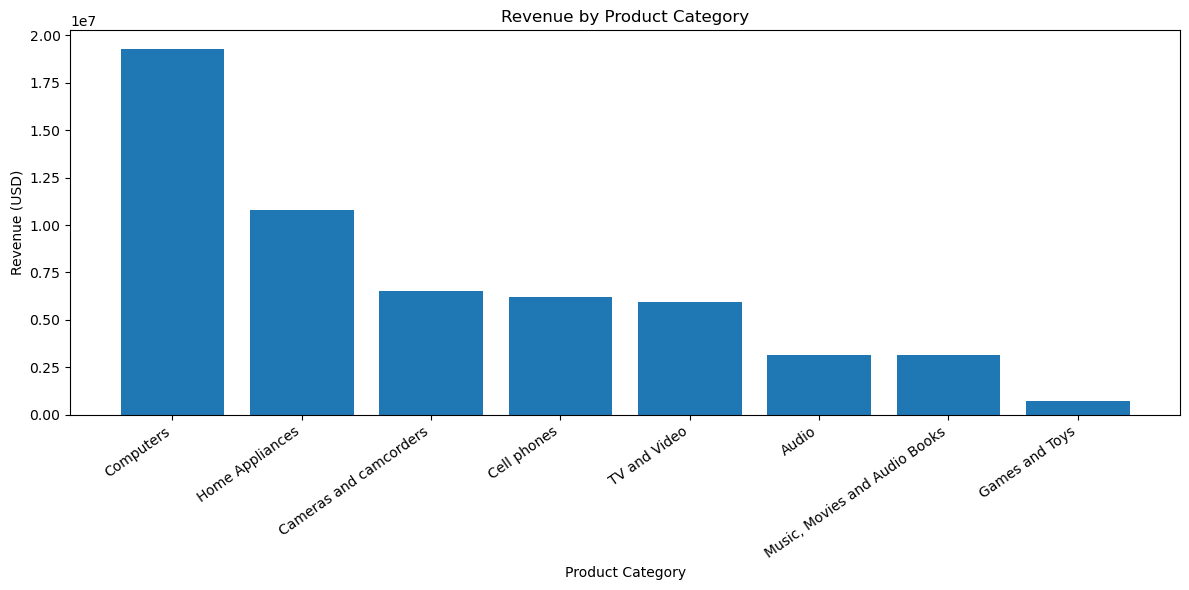

In [21]:
# Revenue by product category

plt.figure(figsize=(12, 6))

plt.bar(
    category_performance["category"].fillna("Unknown").astype(str),
    category_performance["revenue_usd"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (USD)")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [22]:
# Identify the top 10 products by revenue

product_group_columns = ["product_key"]

if "product_name" in sales_enriched.columns:
    product_group_columns.append("product_name")

if "brand" in sales_enriched.columns:
    product_group_columns.append("brand")


top_products = (
    sales_enriched
    .groupby(product_group_columns, dropna=False)
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
    .sort_values("revenue_usd", ascending=False)
    .head(10)
)

display(top_products)

,product_key,product_name,brand,revenue_usd,gross_profit_usd,units_sold
442,444,WWI Desktop PC2.33 X2330 Black,Wide World Importers,"505,450.00","337,986.00",550
414,416,Adventure Works Desktop PC2.33 XD233 Silver,Adventure Works,"466,089.00","311,663.95",481
426,428,Adventure Works Desktop PC2.33 XD233 Brown,Adventure Works,"464,151.00","310,368.05",479
420,422,Adventure Works Desktop PC2.33 XD233 Black,Adventure Works,"447,678.00","299,352.90",462
431,433,Adventure Works Desktop PC2.33 XD233 White,Adventure Works,"437,019.00","292,225.45",451
453,455,WWI Desktop PC2.33 X2330 White,Wide World Importers,"424,578.00","283,908.24",462
448,450,WWI Desktop PC2.33 X2330 Brown,Wide World Importers,"422,740.00","282,679.20",460
146,147,"Adventure Works 52"" LCD HDTV X590 White",Adventure Works,"394,398.64","263,727.12",136
145,146,"Adventure Works 52"" LCD HDTV X590 Black",Adventure Works,"374,098.71","250,152.93",129
436,438,WWI Desktop PC2.33 X2330 Silver,Wide World Importers,"360,248.00","240,891.84",392


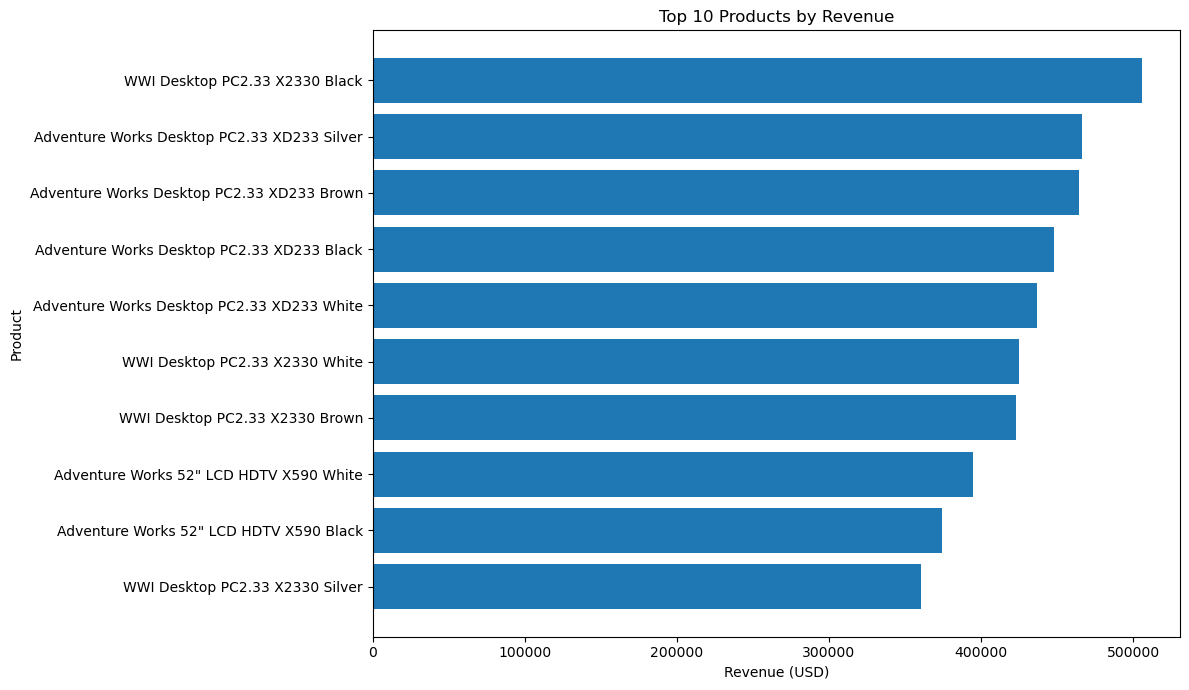

In [23]:
# Visualise the top 10 products

product_labels = (
    top_products["product_name"].astype(str)
    if "product_name" in top_products.columns
    else top_products["product_key"].astype(str)
)

plt.figure(figsize=(12, 7))

plt.barh(
    product_labels,
    top_products["revenue_usd"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (USD)")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 11. Customer Purchasing Behaviour

This section examines customer activity and purchasing patterns.

The analysis investigates:

- Number of unique customers.
- Revenue contribution by customer.
- Average revenue per customer.
- Customer purchasing frequency.
- Customer distribution by gender, where available.

Customer-level analysis helps identify valuable customer segments and opportunities to improve customer retention and engagement.

Revenue per customer is treated as a descriptive performance measure rather than customer lifetime value.

In [24]:
# Customer-level performance

customer_performance = (
    sales_enriched
    .groupby("customer_key")
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        total_units=("quantity", "sum"),
        total_orders=("order_number", "nunique")
    )
    .reset_index()
    .sort_values("revenue_usd", ascending=False)
)

display(customer_performance.head(10))

print(
    "Unique customers:",
    customer_performance["customer_key"].nunique()
)

,customer_key,revenue_usd,gross_profit_usd,total_units,total_orders
9371,1702221,"61,871.70","39,606.02",75,9
10515,1884663,"43,517.80","28,819.96",30,3
11072,1969704,"42,788.04","26,008.23",60,7
2743,535496,"41,521.53","26,957.37",35,3
2840,551036,"40,556.54","26,716.09",36,4
3664,723572,"40,225.01","23,440.78",124,14
1175,262871,"38,813.88","23,986.19",32,3
10795,1928466,"38,191.06","24,054.60",40,4
8116,1503831,"37,319.88","22,881.47",29,3
7275,1373561,"36,817.28","22,954.48",62,5


Unique customers: 11887


In [25]:
# Customer purchasing KPIs

customer_kpis = pd.DataFrame({
    "Metric": [
        "Unique Customers",
        "Average Revenue per Customer",
        "Average Orders per Customer",
        "Average Units per Customer"
    ],
    "Value": [
        customer_performance["customer_key"].nunique(),
        customer_performance["revenue_usd"].mean(),
        customer_performance["total_orders"].mean(),
        customer_performance["total_units"].mean()
    ]
})

display(customer_kpis)

,Metric,Value
0,Unique Customers,"11,887.00"
1,Average Revenue per Customer,"4,690.46"
2,Average Orders per Customer,2.21
3,Average Units per Customer,16.64


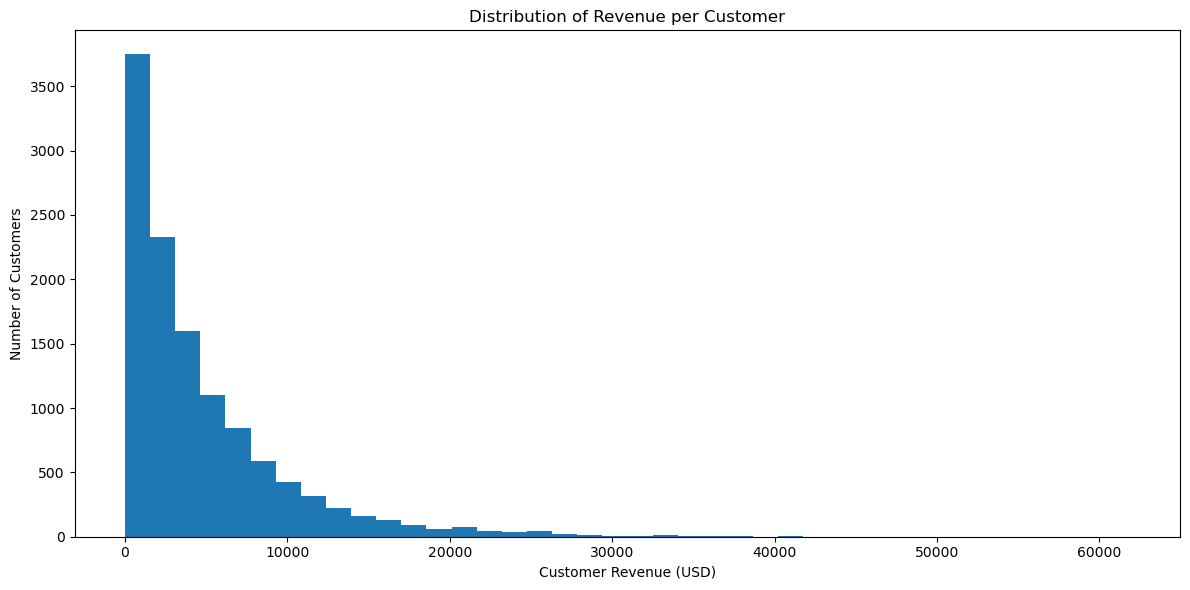

In [26]:
# Customer revenue distribution

plt.figure(figsize=(12, 6))

plt.hist(
    customer_performance["revenue_usd"],
    bins=40
)

plt.title("Distribution of Revenue per Customer")
plt.xlabel("Customer Revenue (USD)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [27]:
# Customer analysis by gender, if available

if "gender" in sales_enriched.columns:

    gender_analysis = (
        sales_enriched
        .groupby("gender", dropna=False)
        .agg(
            revenue_usd=("revenue_usd", "sum"),
            unique_customers=("customer_key", "nunique"),
            orders=("order_number", "nunique")
        )
        .reset_index()
    )

    display(gender_analysis)

else:

    print("Gender information is unavailable.")

,gender,revenue_usd,unique_customers,orders
0,Female,"27,420,624.99",5858,12970
1,Male,"28,334,854.60",6029,13356


## 12. Geographical Sales Performance

This section evaluates the geographical distribution of retail sales.

The analysis examines customer markets using available geographical attributes, including:

- Revenue by country.
- Gross profit by country.
- Number of customers by country.
- Sales contribution by continent.

Geographical analysis can help management identify high-performing markets and areas that may require further commercial investigation.

Customer geography and store geography are treated as separate dimensions.

In [28]:
# Identify available customer geography columns

geography_candidates = [
    "customer_country",
    "country",
    "continent",
    "customer_city",
    "city"
]

available_geography = [
    col for col in geography_candidates
    if col in sales_enriched.columns
]

print("Available geographical fields:")
print(available_geography)


# Country-level analysis
country_column = next(
    (
        col for col in ["customer_country", "country"]
        if col in sales_enriched.columns
    ),
    None
)

if country_column:

    country_performance = (
        sales_enriched
        .groupby(country_column, dropna=False)
        .agg(
            revenue_usd=("revenue_usd", "sum"),
            gross_profit_usd=("gross_profit_usd", "sum"),
            customers=("customer_key", "nunique"),
            orders=("order_number", "nunique"),
            units_sold=("quantity", "sum")
        )
        .reset_index()
        .sort_values("revenue_usd", ascending=False)
    )

    display(country_performance.head(15))

else:

    country_performance = pd.DataFrame()
    print("No customer country field was found.")

Available geographical fields:
['continent', 'city']
No customer country field was found.


In [29]:
# Visualise top 10 countries by revenue

if not country_performance.empty:

    top_countries = country_performance.head(10)

    plt.figure(figsize=(12, 7))

    plt.barh(
        top_countries[country_column].astype(str),
        top_countries["revenue_usd"]
    )

    plt.title("Top 10 Countries by Retail Revenue")
    plt.xlabel("Revenue (USD)")
    plt.ylabel("Country")

    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()

In [30]:
# Analyse revenue by continent

if "continent" in sales_enriched.columns:

    continent_performance = (
        sales_enriched
        .groupby("continent", dropna=False)
        .agg(
            revenue_usd=("revenue_usd", "sum"),
            gross_profit_usd=("gross_profit_usd", "sum"),
            customers=("customer_key", "nunique"),
            orders=("order_number", "nunique")
        )
        .reset_index()
        .sort_values("revenue_usd", ascending=False)
    )

    display(continent_performance)

else:

    continent_performance = pd.DataFrame()
    print("Continent information is unavailable.")

,continent,revenue_usd,gross_profit_usd,customers,orders
2,North America,"34,595,965.80","20,246,662.27",6885,16502
1,Europe,"18,451,376.18","10,818,725.93",4222,8642
0,Australia,"2,708,137.61","1,597,300.18",780,1182


## 13. Product Profitability Analysis

Revenue alone does not provide a complete picture of commercial performance.

This section evaluates the relationship between product revenue, product costs and gross profit.

The analysis investigates:

- Gross profit by product category.
- Gross profit margins.
- Highest-profit products.
- Categories with relatively low gross profit margins.
- Differences between revenue contribution and profitability.

Gross profit represents revenue less direct product costs. It does not account for operating expenses, salaries, rent, distribution overheads or other indirect expenses.

The findings can inform product pricing, purchasing decisions and commercial strategy.

In [31]:
# Calculate profitability by category

profitability_analysis = (
    sales_enriched
    .groupby("category", dropna=False)
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum")
    )
    .reset_index()
)

profitability_analysis["gross_profit_margin"] = np.where(
    profitability_analysis["revenue_usd"] != 0,
    (
        profitability_analysis["gross_profit_usd"] /
        profitability_analysis["revenue_usd"]
    ) * 100,
    np.nan
)

profitability_analysis = profitability_analysis.sort_values(
    "gross_profit_usd",
    ascending=False
)

display(profitability_analysis)

,category,revenue_usd,product_cost_usd,gross_profit_usd,gross_profit_margin
3,Computers,"19,301,595.46","8,024,147.56","11,277,447.90",58.43
5,Home Appliances,"10,795,478.59","4,499,139.74","6,296,338.85",58.32
1,Cameras and camcorders,"6,520,168.02","2,600,367.03","3,919,800.99",60.12
7,TV and Video,"5,928,982.69","2,392,288.30","3,536,694.39",59.65
2,Cell phones,"6,183,791.22","2,685,164.68","3,498,626.54",56.58
6,"Music, Movies and Audio Books","3,131,006.44","1,221,747.27","1,909,259.17",60.98
0,Audio,"3,169,627.74","1,341,775.97","1,827,851.77",57.67
4,Games and Toys,"724,829.43","328,160.66","396,668.77",54.73


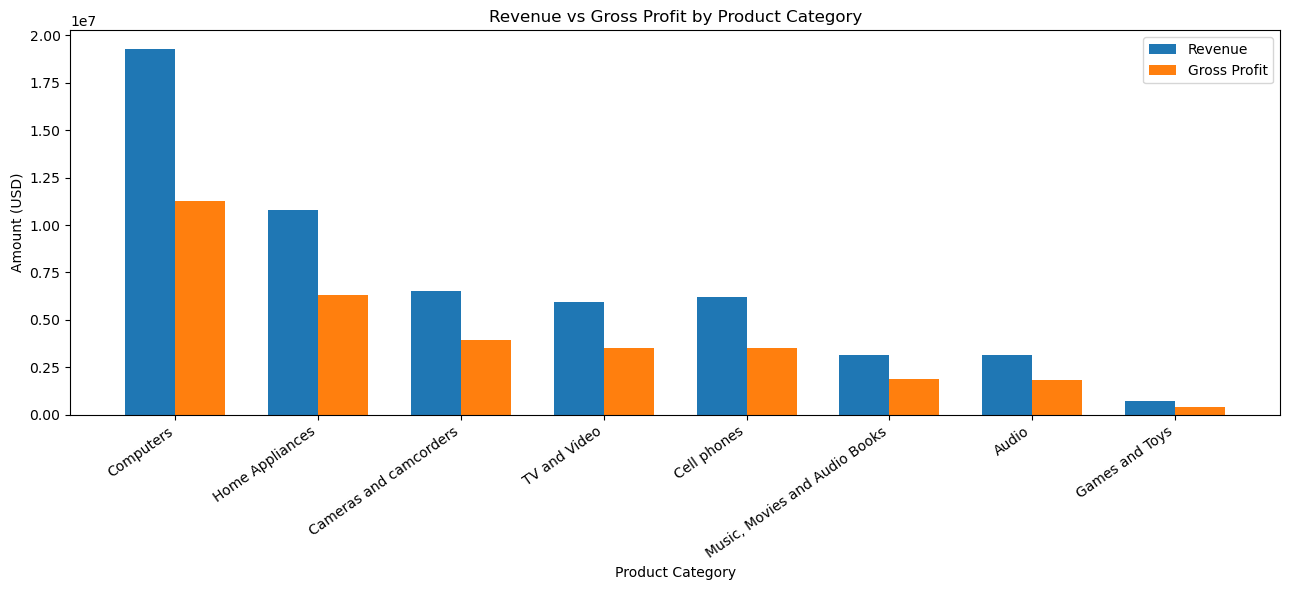

In [32]:
# Compare category revenue and gross profit

x = np.arange(len(profitability_analysis))
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    profitability_analysis["revenue_usd"],
    width,
    label="Revenue"
)

plt.bar(
    x + width / 2,
    profitability_analysis["gross_profit_usd"],
    width,
    label="Gross Profit"
)

plt.title("Revenue vs Gross Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Amount (USD)")

plt.xticks(
    x,
    profitability_analysis["category"].astype(str),
    rotation=35,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# Identify products with the highest gross profit

top_profit_products = (
    sales_enriched
    .groupby(product_group_columns, dropna=False)
    .agg(
        revenue_usd=("revenue_usd", "sum"),
        product_cost_usd=("product_cost_usd", "sum"),
        gross_profit_usd=("gross_profit_usd", "sum"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
    .sort_values("gross_profit_usd", ascending=False)
    .head(10)
)

display(top_profit_products)

,product_key,product_name,brand,revenue_usd,product_cost_usd,gross_profit_usd,units_sold
442,444,WWI Desktop PC2.33 X2330 Black,Wide World Importers,"505,450.00","167,464.00","337,986.00",550
414,416,Adventure Works Desktop PC2.33 XD233 Silver,Adventure Works,"466,089.00","154,425.05","311,663.95",481
426,428,Adventure Works Desktop PC2.33 XD233 Brown,Adventure Works,"464,151.00","153,782.95","310,368.05",479
420,422,Adventure Works Desktop PC2.33 XD233 Black,Adventure Works,"447,678.00","148,325.10","299,352.90",462
431,433,Adventure Works Desktop PC2.33 XD233 White,Adventure Works,"437,019.00","144,793.55","292,225.45",451
453,455,WWI Desktop PC2.33 X2330 White,Wide World Importers,"424,578.00","140,669.76","283,908.24",462
448,450,WWI Desktop PC2.33 X2330 Brown,Wide World Importers,"422,740.00","140,060.80","282,679.20",460
146,147,"Adventure Works 52"" LCD HDTV X590 White",Adventure Works,"394,398.64","130,671.52","263,727.12",136
145,146,"Adventure Works 52"" LCD HDTV X590 Black",Adventure Works,"374,098.71","123,945.78","250,152.93",129
436,438,WWI Desktop PC2.33 X2330 Silver,Wide World Importers,"360,248.00","119,356.16","240,891.84",392


## 14. Key Findings and Business Insights

This section consolidates the findings from the exploratory analysis and translates them into commercially relevant observations.

The analysis considers:

1. Overall revenue and gross profitability.
2. Monthly and annual sales performance.
3. Top-performing product categories.
4. Products contributing the most revenue.
5. Customer purchasing activity.
6. Geographical market performance.
7. Differences between revenue and profitability.

### Management Questions

The findings aim to answer the following questions:

- Which product categories contribute most to revenue?
- Which categories generate the highest gross profit?
- Which products are the strongest commercial performers?
- Are sales increasing or declining over time?
- Which geographical markets contribute most to revenue?
- How concentrated is revenue among customers?
- Which categories have relatively low gross profit margins?

Recommendations should be based on observed results and supported by the analytical outputs.

The findings will inform the development of the Power BI dashboard.

In [34]:
# Generate data-driven business findings

print("=" * 70)
print("RETAIL SALES INTELLIGENCE")
print("KEY BUSINESS FINDINGS")
print("=" * 70)

print("\n1. OVERALL FINANCIAL PERFORMANCE")

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Product Cost: ${total_product_cost:,.2f}")
print(f"Gross Profit: ${total_gross_profit:,.2f}")
print(f"Gross Profit Margin: {overall_gross_margin:.2f}%")
print(f"Total Units Sold: {total_units:,.0f}")
print(f"Total Orders: {total_orders:,.0f}")


print("\n2. TOP PRODUCT CATEGORY")

if not category_performance.empty:

    top_category = category_performance.iloc[0]

    print("Category:", top_category["category"])

    print(
        f"Revenue: ${top_category['revenue_usd']:,.2f}"
    )

    print(
        f"Gross Profit: ${top_category['gross_profit_usd']:,.2f}"
    )


print("\n3. TOP REVENUE-GENERATING PRODUCT")

if not top_products.empty:

    top_product = top_products.iloc[0]

    print(
        "Product:",
        top_product.get("product_name", top_product["product_key"])
    )

    print(
        f"Revenue: ${top_product['revenue_usd']:,.2f}"
    )


print("\n4. CUSTOMER PERFORMANCE")

print(
    f"Unique Customers: "
    f"{customer_performance['customer_key'].nunique():,}"
)

print(
    f"Average Revenue per Customer: "
    f"${customer_performance['revenue_usd'].mean():,.2f}"
)


print("\n5. GEOGRAPHICAL PERFORMANCE")

if not country_performance.empty:

    top_country = country_performance.iloc[0]

    print(
        "Leading Customer Market:",
        top_country[country_column]
    )

    print(
        f"Revenue: ${top_country['revenue_usd']:,.2f}"
    )


print("\n6. TEMPORAL PERFORMANCE")

if not monthly_sales.empty:

    highest_month = monthly_sales.loc[
        monthly_sales["revenue_usd"].idxmax()
    ]

    print("Highest Revenue Month:", highest_month["year_month"])

    print(
        f"Revenue: ${highest_month['revenue_usd']:,.2f}"
    )


print("\nAnalysis findings generated successfully.")

RETAIL SALES INTELLIGENCE
KEY BUSINESS FINDINGS

1. OVERALL FINANCIAL PERFORMANCE
Total Revenue: $55,755,479.59
Total Product Cost: $23,092,791.21
Gross Profit: $32,662,688.38
Gross Profit Margin: 58.58%
Total Units Sold: 197,757
Total Orders: 26,326

2. TOP PRODUCT CATEGORY
Category: Computers
Revenue: $19,301,595.46
Gross Profit: $11,277,447.90

3. TOP REVENUE-GENERATING PRODUCT
Product: WWI Desktop PC2.33 X2330 Black
Revenue: $505,450.00

4. CUSTOMER PERFORMANCE
Unique Customers: 11,887
Average Revenue per Customer: $4,690.46

5. GEOGRAPHICAL PERFORMANCE

6. TEMPORAL PERFORMANCE
Highest Revenue Month: 2019-12
Revenue: $2,477,295.85

Analysis findings generated successfully.


In [35]:
# Compare category profitability

margin_categories = profitability_analysis.dropna(
    subset=["gross_profit_margin"]
)

if not margin_categories.empty:

    highest_margin = margin_categories.loc[
        margin_categories["gross_profit_margin"].idxmax()
    ]

    lowest_margin = margin_categories.loc[
        margin_categories["gross_profit_margin"].idxmin()
    ]

    print("HIGHEST GROSS PROFIT MARGIN")

    print("Category:", highest_margin["category"])

    print(
        f"Margin: {highest_margin['gross_profit_margin']:.2f}%"
    )

    print("\nLOWEST GROSS PROFIT MARGIN")

    print("Category:", lowest_margin["category"])

    print(
        f"Margin: {lowest_margin['gross_profit_margin']:.2f}%"
    )

HIGHEST GROSS PROFIT MARGIN
Category: Music, Movies and Audio Books
Margin: 60.98%

LOWEST GROSS PROFIT MARGIN
Category: Games and Toys
Margin: 54.73%


## 15. Export Analytical Datasets

The final stage exports the enriched transaction dataset and analytical summaries for subsequent use in Power BI.

The exported datasets include:

1. sales_enriched_eda.csv
2. monthly_sales_analysis.csv
3. yearly_sales_analysis.csv
4. category_performance.csv
5. top_products.csv
6. top_profit_products.csv
7. customer_performance.csv
8. country_performance.csv
9. continent_performance.csv
10. profitability_analysis.csv
11. retail_kpi_summary.csv

The original raw and processed datasets remain unchanged.

The exported files will serve as the analytical foundation for the Retail Sales Intelligence dashboard.

In [36]:
# Export enriched transaction-level dataset

sales_enriched.to_csv(
    EDA_OUTPUT_DIR / "sales_enriched_eda.csv",
    index=False
)

# Export monthly and yearly summaries

monthly_sales.to_csv(
    EDA_OUTPUT_DIR / "monthly_sales_analysis.csv",
    index=False
)

yearly_sales.to_csv(
    EDA_OUTPUT_DIR / "yearly_sales_analysis.csv",
    index=False
)

# Export product analysis

category_performance.to_csv(
    EDA_OUTPUT_DIR / "category_performance.csv",
    index=False
)

top_products.to_csv(
    EDA_OUTPUT_DIR / "top_products.csv",
    index=False
)

top_profit_products.to_csv(
    EDA_OUTPUT_DIR / "top_profit_products.csv",
    index=False
)

# Export customer analysis

customer_performance.to_csv(
    EDA_OUTPUT_DIR / "customer_performance.csv",
    index=False
)

# Export geographical analysis

if not country_performance.empty:

    country_performance.to_csv(
        EDA_OUTPUT_DIR / "country_performance.csv",
        index=False
    )

if not continent_performance.empty:

    continent_performance.to_csv(
        EDA_OUTPUT_DIR / "continent_performance.csv",
        index=False
    )

# Export profitability analysis

profitability_analysis.to_csv(
    EDA_OUTPUT_DIR / "profitability_analysis.csv",
    index=False
)

# Export KPI summary

kpi_summary.to_csv(
    EDA_OUTPUT_DIR / "retail_kpi_summary.csv",
    index=False
)

print("All available analytical datasets exported successfully.")

All available analytical datasets exported successfully.


In [37]:
# Verify exported analytical files

print("=" * 65)
print("EXPORTED ANALYTICAL DATASETS")
print("=" * 65)

exported_files = sorted(
    EDA_OUTPUT_DIR.glob("*.csv")
)

for file in exported_files:

    df = pd.read_csv(file)

    print(
        f"{file.name:<40} "
        f"{len(df):>10,} rows"
    )

print("\nTotal exported files:", len(exported_files))

print("\nOutput location:")
print(EDA_OUTPUT_DIR.resolve())

EXPORTED ANALYTICAL DATASETS
category_performance.csv                          8 rows
continent_performance.csv                         3 rows
customer_performance.csv                     11,887 rows
monthly_sales_analysis.csv                       62 rows
profitability_analysis.csv                        8 rows
retail_kpi_summary.csv                            7 rows
sales_enriched_eda.csv                       62,884 rows
top_products.csv                                 10 rows
top_profit_products.csv                          10 rows
yearly_sales_analysis.csv                         6 rows

Total exported files: 10

Output location:
C:\Users\Administrator\retail-sales-intelligence\data\processed\eda_outputs


## 16. Final Validation and Conclusion

The exploratory data analysis has integrated the retail transaction data and examined the retailer's commercial performance.

The analysis covered:

- Data integration and validation.
- Financial feature engineering.
- Descriptive statistics.
- Overall sales performance.
- Temporal revenue patterns.
- Product and category performance.
- Customer purchasing behaviour.
- Geographical performance.
- Product profitability.
- Business insights.

### Analytical Limitations

The analysis focuses on revenue and gross profit rather than net profit because operating expenses and other indirect costs are not included.

Customer revenue is not equivalent to customer lifetime value.

Historical sales patterns do not independently establish the causes of changes in revenue.

### Next Stage

The analytical outputs will be used to develop an interactive Power BI dashboard.

The dashboard will communicate commercial performance through key performance indicators, time-series analysis, product comparisons, customer segmentation and geographical visualisations.

In [38]:
# Final notebook validation

print("=" * 70)
print("NOTEBOOK 02: EXPLORATORY DATA ANALYSIS")
print("FINAL VALIDATION REPORT")
print("=" * 70)

print("\nDATA INTEGRATION")

print(f"Original sales records: {original_sales_count:,}")
print(f"Integrated sales records: {len(sales_enriched):,}")

print(
    "Transaction preservation:",
    "PASSED" if len(sales_enriched) == original_sales_count
    else "FAILED"
)

print("\nFINANCIAL VALIDATION")

for col in [
    "unit_price_usd",
    "unit_cost_usd",
    "revenue_usd",
    "gross_profit_usd"
]:

    print(
        f"{col}: "
        f"{sales_enriched[col].notna().sum():,} valid observations"
    )

print("\nCOMMERCIAL PERFORMANCE")

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Gross Profit: ${total_gross_profit:,.2f}")
print(f"Gross Profit Margin: {overall_gross_margin:.2f}%")

print("\nEXPORTED DATASETS")

print(f"Files generated: {len(exported_files)}")

print("\nOUTPUT DIRECTORY")
print(EDA_OUTPUT_DIR.resolve())

print("\nNOTEBOOK 02 EXECUTION COMPLETED.")

NOTEBOOK 02: EXPLORATORY DATA ANALYSIS
FINAL VALIDATION REPORT

DATA INTEGRATION
Original sales records: 62,884
Integrated sales records: 62,884
Transaction preservation: PASSED

FINANCIAL VALIDATION
unit_price_usd: 62,884 valid observations
unit_cost_usd: 62,884 valid observations
revenue_usd: 62,884 valid observations
gross_profit_usd: 62,884 valid observations

COMMERCIAL PERFORMANCE
Total Revenue: $55,755,479.59
Gross Profit: $32,662,688.38
Gross Profit Margin: 58.58%

EXPORTED DATASETS
Files generated: 10

OUTPUT DIRECTORY
C:\Users\Administrator\retail-sales-intelligence\data\processed\eda_outputs

NOTEBOOK 02 EXECUTION COMPLETED.
